In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.loader import load_parquet

sns.set_theme(style="whitegrid", context="notebook")

train_df = load_parquet("../data/processed/train.parquet")
print(train_df.shape)
train_df.head()

Matplotlib is building the font cache; this may take a moment.


(199364, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.619995,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.690000,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.660004,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.500000,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798279,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.989998,0


Class counts (train set):
  Legitimate (0): 198,980 (99.807%)
  Fraud      (1):     384 (0.193%)
  Imbalance ratio: 1 fraud per 518 legitimate


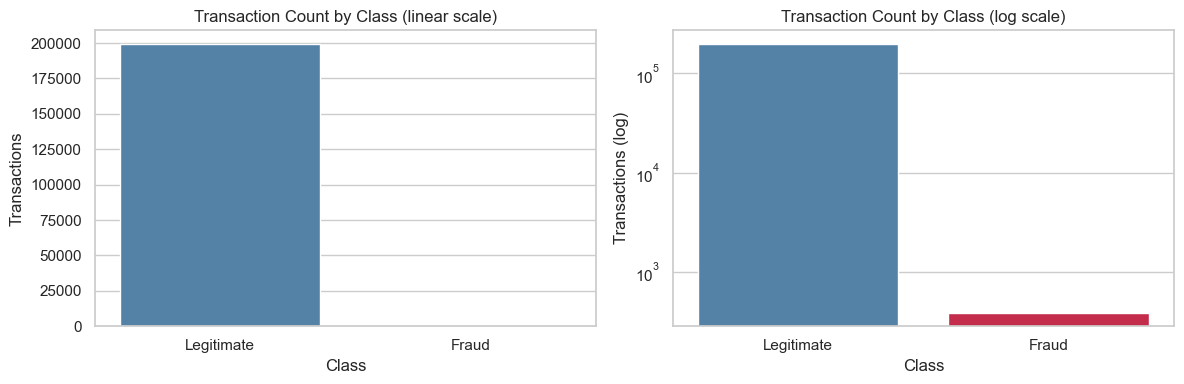

In [2]:
# --- Target distribution ---
counts = train_df["Class"].value_counts()
rates = train_df["Class"].value_counts(normalize=True) * 100

print("Class counts (train set):")
print(f"  Legitimate (0): {counts[0]:>7,} ({rates[0]:.3f}%)")
print(f"  Fraud      (1): {counts[1]:>7,} ({rates[1]:.3f}%)")
print(f"  Imbalance ratio: 1 fraud per {counts[0] // counts[1]:,} legitimate")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=train_df, x="Class", ax=axes[0], hue="Class", palette=["steelblue", "crimson"], legend=False)
axes[0].set_title("Transaction Count by Class (linear scale)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate", "Fraud"])
axes[0].set_ylabel("Transactions")

sns.countplot(data=train_df, x="Class", ax=axes[1], hue="Class", palette=["steelblue", "crimson"], legend=False)
axes[1].set_yscale("log")
axes[1].set_title("Transaction Count by Class (log scale)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_ylabel("Transactions (log)")

plt.tight_layout()
plt.show()

**Observation — target distribution:**

The training set contains 384 fraud cases out of 199,364 transactions
(0.193%), a class imbalance of roughly 1:518. This matters for three
reasons:

1. **Accuracy is useless as a metric.** A model that always predicts
   "legitimate" would be 99.8% accurate yet catch zero fraud.
2. **Class weighting or threshold tuning is required** at training
   time; the default 0.5 threshold on an imbalanced dataset heavily
   favors the majority class.
3. **Precision-Recall AUC is the right primary metric**, not ROC-AUC.
   ROC curves look optimistic under severe imbalance because the
   true-negative rate dominates.

I will revisit all three points in the evaluation phase.

Amount statistics:
                  Legitimate        Fraud
count                198,980          384
mean                   89.72       118.65
median                 23.00        11.85
std                   248.91       248.77
min                     0.00         0.00
max                 19656.53      2125.87
% zero-amount          0.68%        4.69%


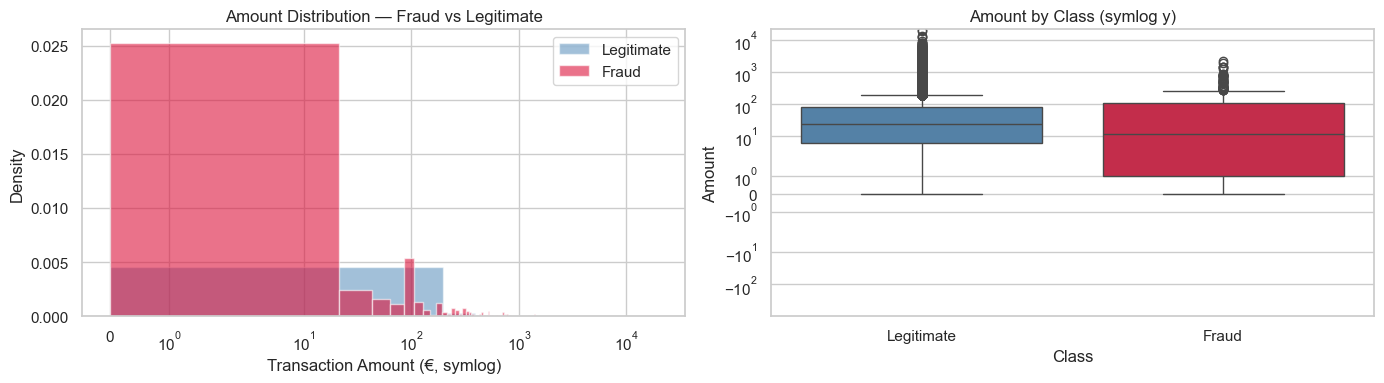

In [3]:
# --- Amount distribution: fraud vs legitimate ---
legit = train_df.loc[train_df["Class"] == 0, "Amount"]
fraud = train_df.loc[train_df["Class"] == 1, "Amount"]

print("Amount statistics:")
print(f"{'':15s} {'Legitimate':>12s} {'Fraud':>12s}")
print(f"{'count':15s} {len(legit):>12,} {len(fraud):>12,}")
print(f"{'mean':15s} {legit.mean():>12.2f} {fraud.mean():>12.2f}")
print(f"{'median':15s} {legit.median():>12.2f} {fraud.median():>12.2f}")
print(f"{'std':15s} {legit.std():>12.2f} {fraud.std():>12.2f}")
print(f"{'min':15s} {legit.min():>12.2f} {fraud.min():>12.2f}")
print(f"{'max':15s} {legit.max():>12.2f} {fraud.max():>12.2f}")
print(f"{'% zero-amount':15s} {(legit == 0).mean()*100:>11.2f}% {(fraud == 0).mean()*100:>11.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: raw distributions (log scale on x because amounts are heavy-tailed)
axes[0].hist(legit, bins=100, alpha=0.5, label="Legitimate", color="steelblue", density=True)
axes[0].hist(fraud, bins=100, alpha=0.6, label="Fraud", color="crimson", density=True)
axes[0].set_xscale("symlog")
axes[0].set_xlabel("Transaction Amount (€, symlog)")
axes[0].set_ylabel("Density")
axes[0].set_title("Amount Distribution — Fraud vs Legitimate")
axes[0].legend()

# Right: boxplot for a direct comparison
sns.boxplot(data=train_df, x="Class", y="Amount", ax=axes[1], hue="Class", palette=["steelblue", "crimson"], legend=False)
axes[1].set_yscale("symlog")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_title("Amount by Class (symlog y)")

plt.tight_layout()
plt.show()

**Observation — amount distribution:**

Fraud amounts are structurally different from legitimate ones in
three measurable ways:

- **Zero-amount transactions are ~7× more common in fraud**
  (4.69% vs 0.68%). This is a card-verification probe: attackers
  ping the issuer with a €0 authorization to confirm the stolen
  card is live, without triggering amount-based alerts. The single
  cleanest fraud signal in interpretable features.
- **Fraud median is roughly half the legitimate median**
  (€11.85 vs €23.00): consistent with card-testing attacks that
  start small and escalate only if undetected.
- **Mean > median for both classes**, but especially pronounced in
  fraud, where a few larger attempts (max €2,126) pull the mean
  (€118.65) well above the typical case. Reporting only mean would
  have hidden the actual fraud behavior.
- **Fraud amounts are capped lower** than legitimate (€2,126 vs
  €19,657): large transactions trigger manual review, so fraudsters
  avoid them.

**Feature engineering implication:** raw `Amount` alone has
overlapping distributions, so it will be weakly discriminative on
its own. Three derived features worth adding later:

1. `is_zero_amount` — binary flag, directly captures the strongest signal
2. `amount_log` — compresses the heavy tail for linear models
3. `amount_vs_customer_average` — once customer identity is available,
   deviation from a customer's own baseline is a stronger signal than
   absolute amount

 hour  total  fraud  fraud_rate_pct
    0   7695      6        0.077973
    1   4220     10        0.236967
    2   3328     57        1.712740
    3   3492     17        0.486827
    4   2209     23        1.041195
    5   2990     11        0.367893
    6   4101      9        0.219459
    7   7243     23        0.317548
    8  10276      9        0.087583
    9  15838     16        0.101023
   10  16598      8        0.048199
   11  16856     53        0.314428
   12  14865     16        0.107635
   13   7585      9        0.118655
   14   8029     13        0.161913
   15   7836     14        0.178663
   16   7786     14        0.179810
   17   7882     12        0.152246
   18   8607     15        0.174277
   19   7994      7        0.087566
   20   8980      8        0.089087
   21   9895     14        0.141486
   22   8977      3        0.033419
   23   6082     17        0.279513


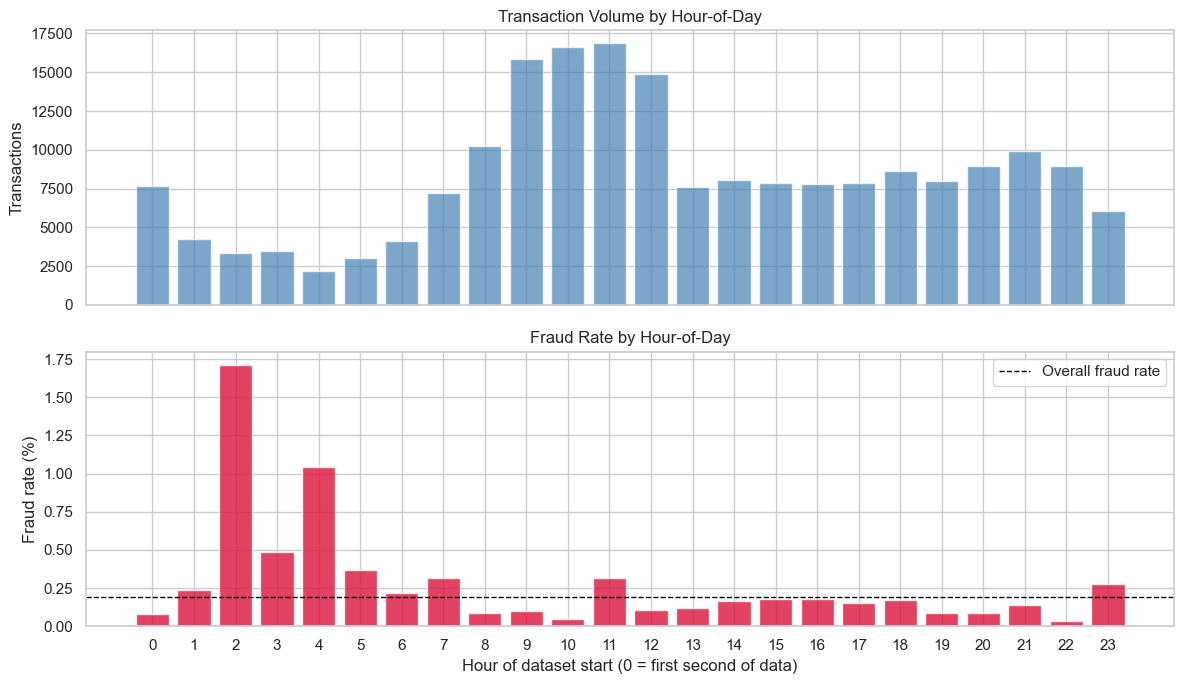

In [4]:
# --- Time patterns: derive hour-of-day and plot fraud rate ---
train_df["hour"] = (train_df["Time"] // 3600) % 24

hourly = train_df.groupby("hour").agg(
    total=("Class", "size"),
    fraud=("Class", "sum"),
).reset_index()
hourly["fraud_rate_pct"] = hourly["fraud"] / hourly["total"] * 100

print(hourly.to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Top: transaction volume by hour
axes[0].bar(hourly["hour"], hourly["total"], color="steelblue", alpha=0.7)
axes[0].set_ylabel("Transactions")
axes[0].set_title("Transaction Volume by Hour-of-Day")

# Bottom: fraud rate by hour
axes[1].bar(hourly["hour"], hourly["fraud_rate_pct"], color="crimson", alpha=0.8)
axes[1].axhline(y=train_df["Class"].mean()*100, color="black", linestyle="--", linewidth=1, label="Overall fraud rate")
axes[1].set_xlabel("Hour of dataset start (0 = first second of data)")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_title("Fraud Rate by Hour-of-Day")
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation — time patterns:**

Fraud rate varies substantially by hour-of-day:

- **Hour 2 shows a 9× elevated fraud rate** (1.71% vs baseline
  0.19%): 57 fraud cases out of 3,328 transactions. Likely the
  combination of (a) low legitimate volume while cardholders sleep
  and (b) automated attacks running on bot schedules.
- **Hour 4 is also elevated** (1.04%, ~5× baseline).
- **Hours 22, 10, 20, 19** are the safest at <0.1% fraud rate — note
  that "late night" is not uniformly risky; the risk concentrates
  in the 2–5 AM window specifically.
- **Hour 11 is an exception**: high volume AND 53 fraud cases
  (0.31% rate). Time-of-day captures *tendencies*, not rules;
  individual bursts can occur during peak hours.

**Feature engineering implication:** add an `is_unusual_hour` binary
flag for the 2–5 AM window as a direct signal, plus `hour` (0–23)
as a cyclic feature. For tree-based models, raw `hour` is fine; for
linear models, encode as sin/cos pair to capture cyclicality.

**Caveat:** "Hour 0" is the first second of the dataset, not literal
midnight. The pattern is still real — relative hour-of-day captures
daily cyclicality — but the clock-time mapping is unknown.

In [5]:
# --- V-feature ranking by fraud/legit separation (Cohen's d) ---
v_cols = [f"V{i}" for i in range(1, 29)]

legit_mask = train_df["Class"] == 0
fraud_mask = train_df["Class"] == 1

results = []
for col in v_cols:
    mean_legit = train_df.loc[legit_mask, col].mean()
    mean_fraud = train_df.loc[fraud_mask, col].mean()
    std_overall = train_df[col].std()
    cohens_d = (mean_fraud - mean_legit) / std_overall
    results.append({"feature": col, "mean_legit": mean_legit,
                    "mean_fraud": mean_fraud, "cohens_d": cohens_d,
                    "abs_d": abs(cohens_d)})

v_ranking = pd.DataFrame(results).sort_values("abs_d", ascending=False).reset_index(drop=True)
print("Top 10 V-features by |Cohen's d| (fraud vs legitimate):")
print(v_ranking.head(10).to_string(index=False))
print("\nBottom 5 (likely noise for this problem):")
print(v_ranking.tail(5).to_string(index=False))

Top 10 V-features by |Cohen's d| (fraud vs legitimate):
feature  mean_legit  mean_fraud  cohens_d    abs_d
    V17    0.041680   -7.757407 -8.755752 8.755752
    V14    0.064687   -7.165640 -7.439847 7.439847
    V12   -0.056669   -6.968545 -6.317576 6.317576
    V10    0.001042   -6.375370 -5.835472 5.835472
     V3    0.336322   -7.731344 -5.573397 5.573397
     V7   -0.037863   -6.644156 -5.423582 5.423582
    V16    0.003179   -4.727077 -5.339437 5.339437
    V11    0.118332    4.179325  3.901358 3.901358
     V4    0.066448    4.760984  3.355088 3.355088
    V18   -0.030855   -2.720504 -3.203508 3.203508

Bottom 5 (likely noise for this problem):
feature  mean_legit  mean_fraud  cohens_d    abs_d
    V13    0.037397   -0.034515 -0.069688 0.069688
    V26    0.006187    0.037829  0.064787 0.064787
    V23   -0.015451   -0.050860 -0.057976 0.057976
    V22   -0.047968   -0.022472  0.036880 0.036880
    V25    0.060797    0.069565  0.017848 0.017848


Plotting distributions for: ['V17', 'V14', 'V12', 'V10']


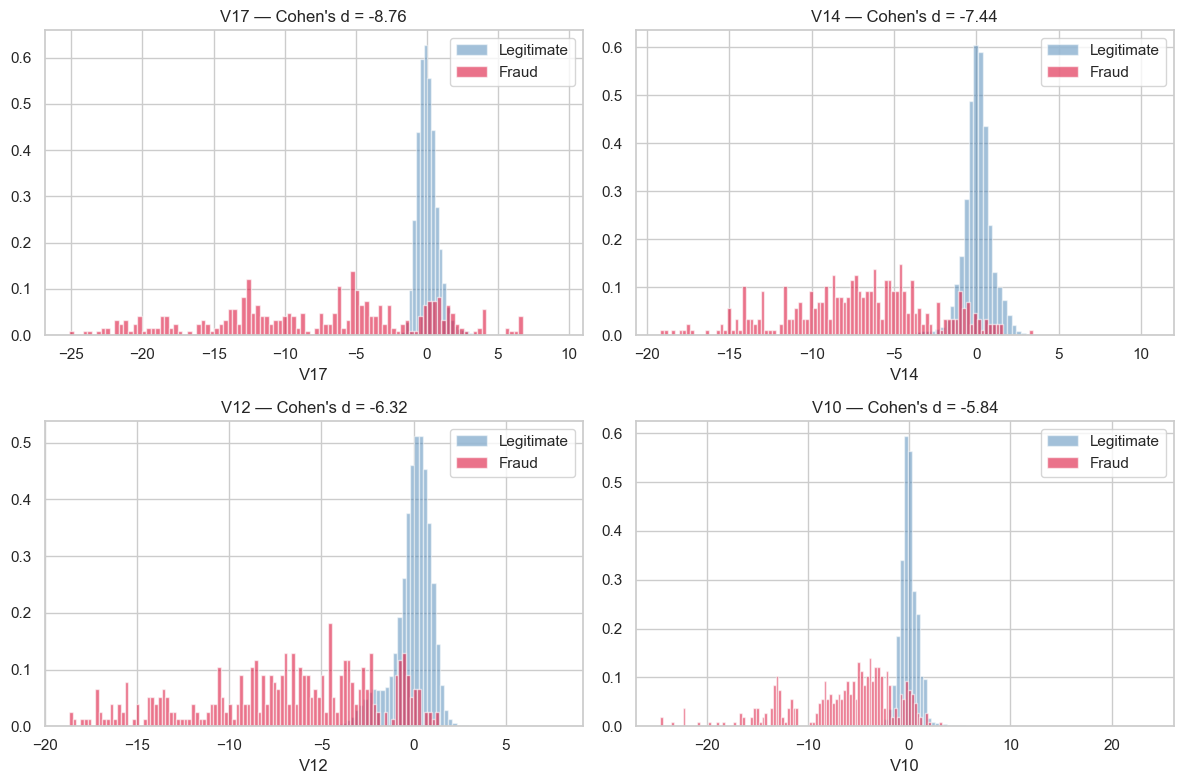

In [6]:
# --- Distributions of the top 4 V-features ---
top4 = v_ranking.head(4)["feature"].tolist()
print(f"Plotting distributions for: {top4}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(top4):
    ax = axes[i]
    ax.hist(train_df.loc[legit_mask, col], bins=100, alpha=0.5,
            label="Legitimate", color="steelblue", density=True)
    ax.hist(train_df.loc[fraud_mask, col], bins=100, alpha=0.6,
            label="Fraud", color="crimson", density=True)
    d = v_ranking.loc[v_ranking["feature"] == col, "cohens_d"].values[0]
    ax.set_title(f"{col} — Cohen's d = {d:+.2f}")
    ax.set_xlabel(col)
    ax.legend()

plt.tight_layout()
plt.show()

**Observation — V-feature discrimination:**

The V-features show unusually strong fraud separation:

- **Top discriminators have Cohen's d ≈ 3–9**: V17 (-8.76),
  V14 (-7.44), V12 (-6.32), V10 (-5.84), V3 (-5.57).
  Fraud transactions sit many standard deviations below the
  legitimate mean on these components.
- **This is a dataset-specific effect**, not a general fraud
  pattern. PCA on labeled transaction data tends to produce
  components that partly encode the rare class, so the "features"
  themselves are structurally correlated with the target.
- **Weakest discriminators** (V13, V26, V23, V22, V25) have
  |d| < 0.1 and are essentially noise on their own.

**Modeling implication:** this dataset is naturally highly
separable. Baseline models will likely score ROC-AUC > 0.95 even
with no tuning. I will therefore use **PR-AUC and precision at
fixed recall** as primary metrics — ROC-AUC becomes uninformative
when separation is this strong.

**Feature retention:** I keep all 28 V-features. Low-d features
can still contribute via interactions in tree-based models;
dropping on univariate analysis alone is a common mistake.

In [7]:
# --- Data quality: missing values & duplicates ---
missing = train_df.isna().sum()
missing_cols = missing[missing > 0]

print("Missing values:")
if len(missing_cols) == 0:
    print("  No missing values in training set.")
else:
    print(missing_cols.to_string())

n_duplicates = train_df.duplicated().sum()
print(f"\nExact duplicate rows: {n_duplicates:,}")

# Check for duplicates excluding Time (same transaction repeated at a different second)
n_dup_excl_time = train_df.drop(columns=["Time"]).duplicated().sum()
print(f"Duplicate rows ignoring Time: {n_dup_excl_time:,}")

# Fraud rate among duplicates (if any)
if n_dup_excl_time > 0:
    dup_mask = train_df.drop(columns=["Time"]).duplicated(keep=False)
    dup_rows = train_df[dup_mask]
    print(f"Fraud rate within duplicate rows: {dup_rows['Class'].mean()*100:.3f}%")

Missing values:
  No missing values in training set.

Exact duplicate rows: 716
Duplicate rows ignoring Time: 2,860
Fraud rate within duplicate rows: 0.650%


In [8]:
# --- Remove exact duplicates from training set only ---
before = len(train_df)
train_df = train_df.drop_duplicates().reset_index(drop=True)
after = len(train_df)

print(f"Removed {before - after} exact duplicate rows.")
print(f"Training set size: {before:,} → {after:,}")
print(f"New fraud rate: {train_df['Class'].mean()*100:.3f}%")

Removed 716 exact duplicate rows.
Training set size: 199,364 → 198,648
New fraud rate: 0.184%


**Observation — data quality:**

- **No missing values** in the training set. No imputation strategy
  needed. (This is a cleaned research dataset; production data will
  not be this tidy, and I would design per-feature imputation in a
  real deployment.)
- **716 exact duplicate rows** (0.36% of training data). Likely
  logging artifacts from the data pipeline — the probability of two
  independent transactions matching on all 31 features including
  `Time` is negligible. **Removed from training only**; validation
  and test splits stay unchanged to reflect real inference-time data.
- **2,860 "near-duplicates"** (identical transactions differing only
  in `Time`) have a 0.65% fraud rate — **3.4× the baseline 0.19%**.
  These are kept: they likely include card-testing probes (same
  attack repeated) and legitimate recurring charges. A derived
  feature `has_recent_identical_transaction` could capture this
  signal; parked for Phase 3.

In [9]:
from src.data.loader import save_parquet

save_parquet(train_df, "../data/processed/train.parquet")
print(f"Overwrote train.parquet with deduplicated set ({len(train_df):,} rows).")

Overwrote train.parquet with deduplicated set (198,648 rows).


In [11]:
from src.features.transformers import AmountFeatures, TimeFeatures

amount_tf = AmountFeatures()
time_tf = TimeFeatures()

sample = train_df.head(10).copy()
sample = amount_tf.fit_transform(sample)
sample = time_tf.fit_transform(sample)

print("New columns added:")
new_cols = ["is_zero_amount", "amount_log", "hour", "is_unusual_hour", "hour_sin", "hour_cos"]
print(sample[["Time", "Amount", "Class"] + new_cols])

New columns added:
   Time      Amount  Class  is_zero_amount  amount_log  hour  is_unusual_hour  \
0     0  149.619995      0               0    5.014760     0                0   
1     0    2.690000      0               0    1.305627     0                0   
2     1  378.660004      0               0    5.939276     0                0   
3     1  123.500000      0               0    4.824306     0                0   
4     2   69.989998      0               0    4.262539     0                0   
5     2    3.670000      0               0    1.541159     0                0   
6     4    4.990000      0               0    1.790091     0                0   
7     7   40.799999      0               0    3.732896     0                0   
8     7   93.199997      0               0    4.545420     0                0   
9     9    3.680000      0               0    1.543298     0                0   

   hour_sin  hour_cos  
0       0.0       1.0  
1       0.0       1.0  
2       0.0      

In [12]:
print(sample[new_cols].dtypes)

is_zero_amount        int8
amount_log         float32
hour                  int8
is_unusual_hour       int8
hour_sin           float32
hour_cos           float32
dtype: object


In [15]:
from sklearn.pipeline import Pipeline
from src.data.loader import load_parquet

# Load all three splits
val_df = load_parquet("../data/processed/val.parquet")
test_df = load_parquet("../data/processed/test.parquet")

# Build the pipeline
feature_pipeline = Pipeline([
    ("amount", AmountFeatures()),
    ("time",   TimeFeatures()),
])

# Fit on train (even though our transformers are stateless, this
# is the correct pattern — never call .fit() on val or test)
train_df_fe = feature_pipeline.fit_transform(train_df)

# Transform val and test using the fitted pipeline
val_df_fe = feature_pipeline.transform(val_df)
test_df_fe = feature_pipeline.transform(test_df)

# Verify
print(f"Train: {train_df.shape} → {train_df_fe.shape}  (+{train_df_fe.shape[1] - train_df.shape[1]} cols)")
print(f"Val:   {val_df.shape} → {val_df_fe.shape}")
print(f"Test:  {test_df.shape} → {test_df_fe.shape}")
print(f"\nNew columns added: {[c for c in train_df_fe.columns if c not in train_df.columns]}")

Train: (198648, 31) → (198648, 37)  (+6 cols)
Val:   (42721, 31) → (42721, 37)
Test:  (42722, 31) → (42722, 37)

New columns added: ['is_zero_amount', 'amount_log', 'hour', 'is_unusual_hour', 'hour_sin', 'hour_cos']


In [14]:
# --- Rebuild train.parquet cleanly from the original full dataset ---
from src.data.loader import load_parquet, save_parquet
from src.data.splitter import time_based_split

# Load the original cleaned transactions (no EDA mutations)
df_full = load_parquet("../data/processed/transactions.parquet")
print(f"Full dataset columns: {df_full.shape[1]}")  # should be 31

# Re-split
train_df, val_df, test_df = time_based_split(df_full)

# Re-deduplicate the training set only
before = len(train_df)
train_df = train_df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(train_df)} duplicates from train.")

# Re-save all three splits
save_parquet(train_df, "../data/processed/train.parquet")
save_parquet(val_df, "../data/processed/val.parquet")
save_parquet(test_df, "../data/processed/test.parquet")

print(f"\nAll splits re-saved. train.parquet columns: {train_df.shape[1]}")  # should be 31

Full dataset columns: 31
Removed 716 duplicates from train.

All splits re-saved. train.parquet columns: 31


In [16]:
from src.features.pipeline import build_feature_pipeline

# Old way (inline Pipeline definition):
# feature_pipeline = Pipeline([("amount", AmountFeatures()), ("time", TimeFeatures())])

# New way (one function call, same result):
feature_pipeline = build_feature_pipeline()

train_df_fe = feature_pipeline.fit_transform(train_df)
val_df_fe   = feature_pipeline.transform(val_df)
test_df_fe  = feature_pipeline.transform(test_df)

print(f"Train FE: {train_df_fe.shape}")
print(f"Val FE:   {val_df_fe.shape}")
print(f"Test FE:  {test_df_fe.shape}")

Train FE: (198648, 37)
Val FE:   (42721, 37)
Test FE:  (42722, 37)


In [17]:
from src.data.loader import save_parquet

save_parquet(train_df_fe, "../data/processed/train_fe.parquet")
save_parquet(val_df_fe,   "../data/processed/val_fe.parquet")
save_parquet(test_df_fe,  "../data/processed/test_fe.parquet")

print("Feature-engineered splits saved.")

Feature-engineered splits saved.
